<a href="https://colab.research.google.com/github/jfypes/analysis-NovaRetail-/blob/main/Proyecto_7_Explorando_factores_de_comportamiento_en_NovaRetail%2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats import pointbiserialr

### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `miembro_premium` y `abandono` presentan tipo de dato `int64`, sin embargo, conceptualmente corresponden a una variable categórica binaria, ya que sus valores representan `premium` o `no premium`(en el caso de  `miembro_premium`) y `sí` o `no` (en el caso de `abandono`) en lugar de una cantidad continua.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas= ['edad','nivel_ingreso','visitas_mes','compras_mes','gasto_publicidad_dirigida','satisfaccion','ingreso_anual']
df[columnas_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


**Diagnóstico inicial de variables numéricas**

- `edad` va de 18 a 75 años, con media (38.3) y mediana (38) casi idénticas, lo que indica una distribución bastante simétrica.
- `nivel_ingreso` la media (≈30,020) y la mediana (≈30,023) prácticamente coinciden. El mínimo es 8,000 y el máximo 74,790, lo que sugiere un posible valor atípico alto, pues está muy por encima del percentil 75 (≈36,768).
- `visitas_mes` el mínimo es 1 (ningún usuario con 0 visitas) y el máximo es 25, mientras que el 75% de los usuarios tiene 12 o menos. Ese máximo es más del doble del percentil 75, así que conviene revisarlo.
- `compras_mes` la media es baja (≈1.2) y el percentil 25 es 0, es decir, al menos una cuarta parte de los usuarios no compra nada en el mes. El máximo es 8, bastante alejado del 75% (2).
- `gasto_publicidad_dirigido` el mínimo es 0 y el máximo 75.51, con media de ≈20.1. Hay usuarios sin inversión publicitaria y algunos con gasto muy superior al percentil 75 (≈27.3).
- `satisfaccion` se mueve en una escala de 1 a 5, con media (≈3.6) y mediana (3.6) iguales y desviación baja (≈0.69). La mayoría de los usuarios se concentra en valores medios-altos.
- `ingreso_anual` es la columna con mayor asimetría. La media (≈36.6) está por encima de la mediana (≈30.7), y el máximo (≈244.7) es muy superior al percentil 75 (≈58.22), lo que indica una cola derecha larga con valores atípicos altos.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
df['miembro_premium'].unique()

array([0, 1])

In [ ]:
df['abandono'].unique()

array([0, 1])

**Diagnóstico inicial de variables binarias**

- `miembro_premium`: unique() devuelve [0, 1], es decir, la columna solo contiene dos valores posibles y está codificada como 0/1 (no premium / premium), sin categorías inesperadas ni errores de captura. Detalle relevante: no aparece NaN entre los valores únicos, por lo que no hay nulos en esta columna.
- `abandono`: unique() devuelve [0, 1], es decir, la columna es binaria (0 = el usuario permanece, 1 = abandona) y no contiene valores intermedios ni categorías inesperadas. Detalle relevante: no aparece NaN entre los valores únicos, por lo que no hay nulos. Esto es importante porque cualquier análisis de retención o abandono se vería sesgado si faltaran registros en esta columna.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
df['tipo_dispositivo'].unique()

array(['móvil', 'tablet', 'escritorio'], dtype=object)

In [ ]:
df['region'].unique()

array(['norte', 'sur', 'este', 'oeste'], dtype=object)

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
df['tipo_dispositivo'].describe()

count     15000
unique        3
top       móvil
freq       9818
Name: tipo_dispositivo, dtype: object

In [ ]:
df['tipo_dispositivo'].value_counts()

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

In [ ]:
df['tipo_dispositivo'].value_counts(normalize=True)*100

móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: tipo_dispositivo, dtype: float64

In [ ]:
df['region'].describe()

count     15000
unique        4
top       norte
freq       4395
Name: region, dtype: object

In [ ]:
df['region'].value_counts()

norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

In [ ]:
df['region'].value_counts(normalize=True)*100

norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64

**Diagnóstico inicial de variables categóricas**

- `tipo_dispositivo`: tiene 3 categorías (móvil, escritorio y tablet) y las 15,000 filas están completas, sin nulos. Detalle relevante: hay un claro predominio de móvil con 9,818 registros (≈65.5%), seguido de escritorio con 3,720 (≈24.8%), mientras que tablet es la categoría minoritaria con 1,462 (≈9.7%). Los valores están escritos de forma consistente, sin variantes ni errores de captura.
  
- `region`: tiene 4 categorías (norte, oeste, sur y este) y también cuenta con 15,000 valores, sin nulos. Detalle relevante: la distribución es más equilibrada que la del dispositivo, con norte como la región más frecuente (4,395 registros, ≈29.3%) y este como la menos frecuente (3,069 registros, ≈20.5%), una diferencia de unos 9 puntos porcentuales entre ambas.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

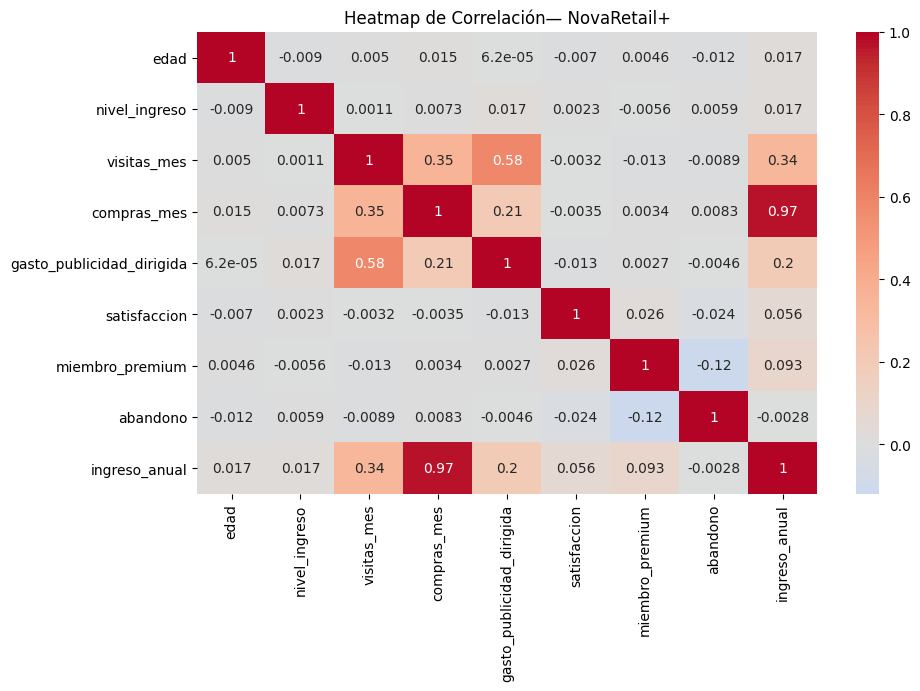

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas_2= ['edad','nivel_ingreso','visitas_mes','compras_mes','gasto_publicidad_dirigida','satisfaccion','miembro_premium', 'abandono','ingreso_anual']
corr = df[columnas_numericas_2].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Heatmap de Correlación— NovaRetail+")
plt.show()

**Observaciones generales (Heatmap)**  
* Se observa que la mayoría de las variables tiene correlaciones cercanas a 0 entre sí, por lo que el heatmap es en gran parte neutro (color gris). Solo unas pocas relaciones destacan.
* **Correlaciones positivas más fuertes:**
  * `compras_mes` e `ingreso_anual` (0.97): es, con mucha diferencia, la relación más fuerte del conjunto.
  * `visitas_mes` y `gasto_publicidad_dirigida` (0.58): correlación moderada-alta.
  * `visitas_mes` y `compras_mes` (0.35) y `visitas_mes` e `ingreso_anual` (0.34): correlaciones moderadas-bajas.
  * `compras_mes` y `gasto_publicidad_dirigida` (0.21) y `gasto_publicidad_dirigida` e `ingreso_anual` (0.20): correlaciones débiles.
* **Correlaciones negativas:** son escasas y de poca magnitud. La más notable es `miembro_premium` con `abandono` (-0.12), que es débil. También aparece `satisfaccion` con `abandono` (-0.024), prácticamente nula.
* **Relaciones débiles o irrelevantes:** `edad` y `nivel_ingreso` tienen correlaciones casi nulas con todas las demás variables (valores entre -0.012 y 0.017). Lo mismo ocurre con `satisfaccion`, cuyas correlaciones están cerca de 0 (la mayor es 0.056 con `ingreso_anual`). `abandono` también tiene correlaciones muy bajas con todas las variables (la más alta en valor absoluto es -0.12).
* **Posibles grupos de variables que se mueven juntas:**
  * Un bloque de comportamiento comercial: `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida` e `ingreso_anual`, que presentan correlaciones positivas entre sí.
  * Un grupo de variables prácticamente independientes del resto: `edad`, `nivel_ingreso` y `satisfaccion`.

Observaciones respecto a `ingreso_anual`  
* Presenta una correlación muy alta con `compras_mes` (0.97), lo que significa que ambas variables se mueven casi a la par. Esto es esperable, ya que `ingreso_anual` representa lo que el cliente genera a la empresa y este depende en buena parte de sus compras. Es posible que `ingreso_anual` se haya construido a partir de `compras_mes` (por ejemplo, extrapolando las compras a 12 meses), lo cual convendría verificar. En ese caso, ambas variables aportarían información redundante y habría riesgo de multicolinealidad si se usan juntas en un modelo. En cualquier caso, la correlación por sí sola no implica causalidad.
* Con `visitas_mes` (0.34) y `gasto_publicidad_dirigida` (0.20) la relación es positiva pero de débil a moderada.
* Con `miembro_premium` (0.093) y `satisfaccion` (0.056) la relación es muy débil.
* Con `edad` (0.017), `nivel_ingreso` (0.017) y `abandono` (-0.0028) es prácticamente nula. En el caso de `nivel_ingreso`, esto es coherente con su definición: mide el ingreso estimado del cliente, mientras que `ingreso_anual` refleja el ingreso que el cliente genera a la empresa, por lo que no tienen por qué moverse juntas.

**Nota metodológica:** una correlación de 0.97 entre dos predictores puede generar multicolinealidad si se usan juntos en un modelo, por lo que habría que decidir si conservar ambas variables. Además, el coeficiente de correlación (de Pearson) solo mide relaciones lineales, y en variables con outliers o asimetría, como `ingreso_anual`, los valores extremos pueden influir en su magnitud.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

**Decisión: no generar un scatterplot general**

Con base en el análisis de correlación, se decide no generar un scatterplot general (todas las variables contra todas), por las siguientes razones:

* **Pocas relaciones destacadas.** La mayoría de las variables presenta correlaciones cercanas a 0. Solo unos pocos pares muestran relación apreciable: `compras_mes` e `ingreso_anual` (0.97), `visitas_mes` y `gasto_publicidad_dirigida` (0.58), y en menor medida `visitas_mes` con `compras_mes` (0.35) e `ingreso_anual` (0.34). El resto de las combinaciones aportaría poco valor.
* **Variables no aptas para un scatterplot.** `miembro_premium`, `abandono`, `tipo_dispositivo` y `region` son binarias o categóricas, por lo que otros gráficos (barras o boxplots por grupo) describen mejor su comportamiento.
* **Eficiencia y legibilidad.** Con 15,000 registros y varias variables, un scatterplot general sería lento de generar y difícil de leer, con muchos paneles sin información relevante.
* **Las conclusiones ya están respaldadas.** La matriz de correlación y las estadísticas descriptivas permiten identificar los pares relevantes sin necesidad de visualizarlos todos.

Como limitación, la correlación de Pearson solo mide relaciones lineales y puede verse afectada por outliers, por lo que, si más adelante se requiere confirmar la forma de alguna relación (por ejemplo, `compras_mes` vs `ingreso_anual`), se podrá generar un gráfico puntual para ese par.

### Scatterplot para pares clave

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes

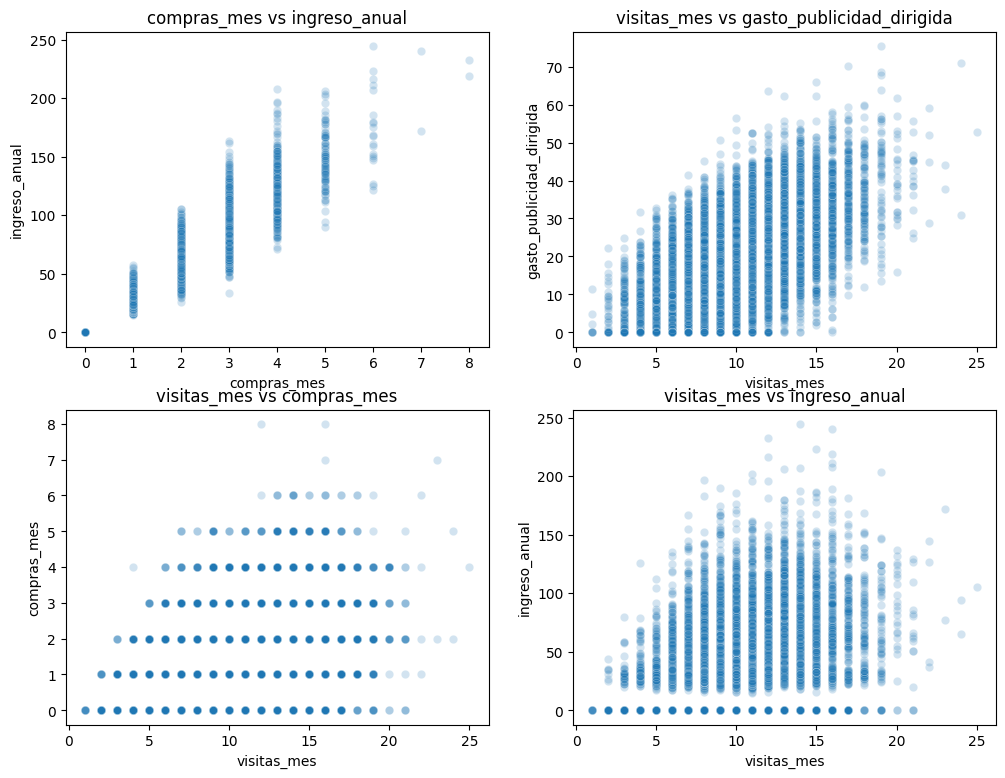

In [ ]:
pares = [
    ('compras_mes', 'ingreso_anual'),
    ('visitas_mes', 'gasto_publicidad_dirigida'),
    ('visitas_mes', 'compras_mes'),
    ('visitas_mes', 'ingreso_anual'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (x, y) in zip(axes.flat, pares):
    sns.scatterplot(data=df, x=x, y=y, alpha=0.2, ax=ax)
    ax.set_title(f'{x} vs {y}')
plt.show()


**Observaciones iniciales (Scatterplot)**

**Criterio de selección:** se graficaron los pares con |r| ≥ 0.30. Se considera correlación moderada el rango de 0.30 a 0.50 y fuerte la superior a 0.50. Los pares con correlaciones menores (por ejemplo, 0.21 y 0.20) se consideraron débiles y no se incluyeron.


**`compras_mes` vs `ingreso_anual`**

* **Dirección:** positiva y muy marcada.
* **Dispersión y clusters:** como `compras_mes` toma valores enteros (0 a 8), los puntos forman columnas verticales. Todos los clientes con 0 compras tienen `ingreso_anual` igual a 0, lo que forma un cluster aparte en el origen. La dispersión crece con el número de compras: con 1 compra el ingreso va aproximadamente de 15 a 55, y con 5 o 6 compras el rango se amplía a más de 100 unidades (forma de abanico).
* **Linealidad:** la tendencia es claramente lineal, con una pendiente casi constante entre columnas.
* **Outliers:** no se observan puntos claramente desconectados de la tendencia general. Los valores más altos de `ingreso_anual` (cercanos a 245) aparecen con 6 a 8 compras y siguen el patrón ascendente, por lo que parecen extremos coherentes con la relación y no errores. Esto es consistente con la cola derecha observada en `ingreso_anual` de forma individual: los valores altos de la columna se explican, en buena parte, por clientes con muchas compras.
* **Colinealidad:** alta, coherente con la correlación de 0.97. Ambas variables aportan información muy parecida.

**`visitas_mes` vs `gasto_publicidad_dirigida`**

* **Dirección:** positiva y moderada.
* **Dispersión y clusters:** los puntos forman columnas por ser `visitas_mes` entera. Hay una línea de puntos en `gasto_publicidad_dirigida` = 0 en casi todos los niveles de visitas. El límite superior del gasto sube con las visitas, y la nube tiene forma de cuña que se abre hacia la derecha.
* **Linealidad:** tendencia aproximadamente lineal, pero con mucha variabilidad. Para un mismo número de visitas el gasto puede ir de 0 a más de 40.
* **Outliers:** pocos puntos altos y aislados, por ejemplo cerca de 75 con unas 16 visitas y alrededor de 70 con 24 visitas. Con más de 20 visitas hay muy pocos registros.
* **Colinealidad:** moderada (0.58). Conviene tenerla presente, pero no es tan fuerte como la del primer par.

**`visitas_mes` vs `compras_mes`**

* **Dirección:** positiva y moderada (0.35).
* **Dispersión y clusters:** al ser ambas variables enteras, los puntos forman una cuadrícula. La mayor concentración está en 0 a 2 compras para casi todos los niveles de visitas. Con pocas visitas (menos de unas 7) casi no hay clientes con más de 2 compras, y los valores de 6 o más aparecen solo desde unas 12 visitas.
* **Linealidad:** no es claramente lineal. Se ve más bien un límite superior que sube con las visitas, sin una nube que siga una línea.
* **Outliers:** los puntos con 7 y 8 compras (por ejemplo, con unas 12 y 16 visitas) se separan del resto. Hay también casos con 22 a 24 visitas y 4 a 7 compras, pero son muy escasos.
* **Colinealidad:** baja. Al estar en el rango bajo de lo moderado, no parece preocupante.

**`visitas_mes` vs `ingreso_anual`**

* **Dirección:** positiva y moderada (0.34).
* **Dispersión y clusters:** hay dos grupos: una línea de puntos en `ingreso_anual` = 0 en todos los niveles de visitas (corresponde a los clientes sin compras) y una nube por encima. La nube se ensancha hasta unas 12 a 16 visitas y se vuelve más rala con más de 18.
* **Linealidad:** no es claramente lineal. El cluster en 0 y la dispersión amplia hacen que el patrón sea difuso. La aparente curvatura al final podría deberse a los pocos registros en ese rango.
* **Outliers:** algunos puntos altos se distinguen, como cerca de 245 con unas 14 visitas, 240 con 16 y 205 con 20.
* **Colinealidad:** baja. Su relación depende en parte de la que ambas tienen con `compras_mes`.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman
La correlación Pearson evalúa relación lineal.
La correlación Spearman evalúa consistencia (monotonía).

La similitud entre ambos valores sugiere una relación moderadamente lineal entre visitas y compras.

In [ ]:
# Función para el cálculo de coeficientes de correlación Pearson/Spearman
def corr_numerica(df, columnas, metodo='pearson'):
    matriz = df[columnas].corr(method=metodo)
    return matriz.style.background_gradient(cmap='coolwarm')

In [ ]:
#Variables relevantes
columnas_numericas_relevantes = ['visitas_mes','compras_mes','gasto_publicidad_dirigida','ingreso_anual']

In [ ]:
# Calcular correlación entre variables relevantes usando Pearson
corr_matriz = corr_numerica(df, columnas_numericas_relevantes, metodo='pearson')
corr_matriz

,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.000000,0.353844,0.578947,0.337147
compras_mes,0.353844,1.000000,0.207528,0.967149
gasto_publicidad_dirigida,0.578947,0.207528,1.000000,0.197483
ingreso_anual,0.337147,0.967149,0.197483,1.000000


In [ ]:
# Calcular correlación entre variables relevantes usando Spearman
corr_matriz = corr_numerica(df, columnas_numericas_relevantes, metodo='spearman')
corr_matriz

,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.000000,0.332943,0.559267,0.320954
compras_mes,0.332943,1.000000,0.192511,0.967482
gasto_publicidad_dirigida,0.559267,0.192511,1.000000,0.184999
ingreso_anual,0.320954,0.967482,0.184999,1.000000


**Observaciones generales (Pearson vs Spearman)**

* Las dos matrices son muy parecidas: la diferencia entre Pearson y Spearman es de aproximadamente 0.01 a 0.02 en todos los pares. Esto sugiere que las relaciones son consistentes y no dependen de unos pocos valores extremos.
* Todas las correlaciones son positivas. No aparece ninguna relación negativa entre estas cuatro variables.
* Siguiendo el criterio definido (débil < 0.30, moderada 0.30 a 0.50, fuerte > 0.50), hay un par muy fuerte, un par fuerte, dos moderados y dos débiles.

**`visitas_mes`**

* Con `gasto_publicidad_dirigida`: positiva y fuerte (Pearson 0.58, Spearman 0.56). Es su relación más alta.
* Con `compras_mes`: positiva y moderada (Pearson 0.35, Spearman 0.33).
* Con `ingreso_anual`: positiva y moderada (Pearson 0.34, Spearman 0.32).
* Colinealidad: no preocupante. Ninguna de sus correlaciones se acerca a niveles altos de redundancia.

**`compras_mes`**

* Con `ingreso_anual`: positiva y muy fuerte (Pearson 0.967, Spearman 0.967). Es, por mucho, la relación más alta de la matriz. Que ambos coeficientes coincidan indica que la relación es consistente (a más compras, más ingreso, sin retrocesos) y aproximadamente lineal.
* Con `visitas_mes`: positiva y moderada (0.35 / 0.33).
* Con `gasto_publicidad_dirigida`: positiva y débil (0.21 / 0.19).
* Colinealidad: alta con `ingreso_anual`. Ambas variables aportan información muy similar, por lo que usarlas juntas en un modelo puede generar multicolinealidad.

**`gasto_publicidad_dirigida`**

* Con `visitas_mes`: positiva y fuerte (0.58 / 0.56).
* Con `compras_mes`: positiva y débil (0.21 / 0.19).
* Con `ingreso_anual`: positiva y débil (0.20 / 0.18). Es su relación más baja.
* Colinealidad: baja a moderada. Su vínculo más alto (0.58) es notable, pero está por debajo de los umbrales habituales de preocupación (alrededor de 0.80 a 0.90).

**`ingreso_anual`**

* Con `compras_mes`: positiva y muy fuerte (0.967 / 0.967).
* Con `visitas_mes`: positiva y moderada (0.34 / 0.32). Esta relación puede depender en parte de la que ambas tienen con `compras_mes`.
* Con `gasto_publicidad_dirigida`: positiva y débil (0.20 / 0.18).
* Colinealidad: alta únicamente con `compras_mes`. Con las demás variables no hay señales de redundancia.

**Conclusión sobre colinealidad**

* El único par con colinealidad alta es `compras_mes` e `ingreso_anual` (≈0.97). El resto de los pares queda en un rango bajo o moderado, sin riesgo evidente.
* Estas correlaciones describen asociación entre variables y no implican causalidad.



### Punto-biserial

In [ ]:
# Función para calcular Punto-biserial
def corr_punto_biserial(df, variables_binarias, variables_numericas):
    for col_bin in variables_binarias:
        for col_num in variables_numericas:
            coef, p_value = pointbiserialr(df[col_bin], df[col_num])
            conjuncion = 'e' if col_num.lower().startswith(('i')) else 'y'
            print(f'\nCorrelación entre: {col_bin} {conjuncion} {col_num}')
            print(f"Point-Biserial: {coef:.4f}")

In [ ]:
columnas_binarias = ['miembro_premium', 'abandono']

In [ ]:
# aplicar Punto-biserial en variables relevantes
corr_punto_biserial(df, columnas_binarias, columnas_numericas_relevantes)


Correlación entre: miembro_premium y visitas_mes
Point-Biserial: -0.0127

Correlación entre: miembro_premium y compras_mes
Point-Biserial: 0.0034

Correlación entre: miembro_premium y gasto_publicidad_dirigida
Point-Biserial: 0.0027

Correlación entre: miembro_premium e ingreso_anual
Point-Biserial: 0.0931

Correlación entre: abandono y visitas_mes
Point-Biserial: -0.0089

Correlación entre: abandono y compras_mes
Point-Biserial: 0.0083

Correlación entre: abandono y gasto_publicidad_dirigida
Point-Biserial: -0.0046

Correlación entre: abandono e ingreso_anual
Point-Biserial: -0.0028


**Observaciones generales (Point-Biserial)**

* Todas las correlaciones son prácticamente nulas: el valor absoluto más alto es 0.0931 y el resto está por debajo de 0.013. Con el criterio definido (0.1 < débil < 0.30), todas caen en la categoría de **no hay relación**.
* Hay direcciones positivas y negativas, pero con valores tan cercanos a 0 la dirección no tiene interpretación práctica.
* No se observa colinealidad entre las variables binarias y las numéricas.

**`miembro_premium`**

* Con `visitas_mes`: negativa y muy baja (-0.0127).
* Con `compras_mes`: positiva y muy baja (0.0034).
* Con `gasto_publicidad_dirigida`: positiva y muy baja (0.0027).
* Con `ingreso_anual`: positiva y baja (0.0931). Es la relación más alta de esta variable y de toda la salida, aunque sigue siendo débil. Una posible lectura es que los miembros premium tienden a generar un ingreso algo mayor, pero la asociación es mínima.

**`abandono`**

* Con `visitas_mes`: negativa y muy baja (-0.0089).
* Con `compras_mes`: positiva y muy baja (0.0083).
* Con `gasto_publicidad_dirigida`: negativa y muy baja (-0.0046).
* Con `ingreso_anual`: negativa y muy baja (-0.0028). Es la relación más cercana a 0 de toda la salida.

**Conclusión**

* Ninguna de las dos variables binarias muestra una relación lineal relevante con las numéricas analizadas. El único valor que se distingue levemente es `miembro_premium` con `ingreso_anual` (0.0931), pero sigue siendo de magnitud baja.
* Estas correlaciones describen asociación y no implican causalidad.




### V de Cramér

In [ ]:
# Función para calcular V de Cramér
def cramer_v(df, col1, col2):
    # tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # calcular chi-cuadrado
    chi2, p_value, dof, expected = chi2_contingency(tabla)

    # calcular coeficiente V de Cramér
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))

    print(f"V de Cramér ({col1} vs {col2}):", v)
    return v

In [ ]:
cramer_v(df,'tipo_dispositivo', 'region')

V de Cramér (tipo_dispositivo vs region): 0.012378338407739397


0.012378338407739397

**Observaciones V de Cramér**

* **Resultado:** la V de Cramér entre `tipo_dispositivo` y `region` es ≈ 0.0124.
* **Magnitud:** muy baja. La V va de 0 (sin asociación) a 1 (asociación perfecta), así que un valor cercano a 0.01 indica una asociación prácticamente nula entre ambas variables.
* **Interpretación:** la distribución de los tipos de dispositivo es muy similar en las cuatro regiones (norte, sur, este y oeste). Conocer la región del cliente casi no aporta información sobre el dispositivo que usa, y viceversa.
* **Colinealidad:** no hay señales de redundancia entre estas dos variables categóricas, por lo que pueden usarse juntas en un análisis o modelo sin riesgo de solapamiento.
* **Nota:** la V de Cramér mide solo la fuerza de la asociación, no su dirección, y no implica causalidad.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---


### Hallazgo 1 — Las compras mensuales y el ingreso anual presentan una asociación muy fuerte

**Evidencia visual:** en el scatterplot `compras_mes` vs `ingreso_anual` los puntos forman columnas verticales (`compras_mes` toma valores enteros de 0 a 8) y el ingreso aumenta de una columna a la siguiente de forma aproximadamente constante. Los clientes con 0 compras aparecen únicamente con `ingreso_anual` = 0. La dispersión del ingreso dentro de cada columna crece con el número de compras: con 1 compra va aproximadamente de 15 a 55, y con 5 o 6 compras el rango supera las 100 unidades.

**Evidencia numérica:** correlación de 0.967 tanto con Pearson como con Spearman. Es la más alta de todos los pares analizados.

**Interpretación:** los clientes con más compras mensuales tienden a registrar un mayor ingreso anual. La relación es positiva en todo el rango de compras y aproximadamente lineal. Los valores más altos de ingreso se observan en clientes con 5 o más compras.

**No podemos afirmar:** que más compras causen un mayor ingreso (ni lo contrario). Tampoco cómo se construyó `ingreso_anual` ni si se deriva de `compras_mes`. No sabemos por qué el ingreso varía entre clientes con el mismo número de compras, porque no se analizó el monto por compra ni otras variables. Y no podemos asegurar que ambas variables puedan usarse juntas en un modelo sin redundancia.

**Implicación de negocio:** `compras_mes` es, entre las variables analizadas, la más asociada al ingreso anual por cliente, por lo que puede servir como indicador de seguimiento. Como ambas variables aportan información muy similar, al modelar habrá que decidir cuál conservar o tratarlas con cuidado por la posible multicolinealidad. Saber si aumentar las compras elevaría el ingreso requeriría otro tipo de análisis; con estos datos no es posible.


### Hallazgo 2 — Al menos una cuarta parte de los clientes registra 0 compras en el mes

**Evidencia visual:** en el scatterplot `visitas_mes` vs `compras_mes` hay una fila de puntos en `compras_mes` = 0 en casi todos los niveles de visitas (desde 1 hasta cerca de 21). En `visitas_mes` vs `ingreso_anual` hay una fila equivalente en `ingreso_anual` = 0.

**Evidencia numérica:** el percentil 25 de `compras_mes` es 0 (mediana 1, media ≈ 1.21), y el percentil 25 de `ingreso_anual` también es 0. El mínimo de `visitas_mes` es 1, es decir, todos los clientes registran al menos una visita. Las correlaciones de `visitas_mes` con `compras_mes` (0.35 Pearson / 0.33 Spearman) y con `ingreso_anual` (0.34 / 0.32) son moderadas.

**Interpretación:** hay clientes con una o más visitas y 0 compras en el mes, y la asociación entre visitas y compras es moderada. En el scatterplot, los clientes con 0 compras aparecen con `ingreso_anual` = 0.

**No podemos afirmar:** la proporción exacta de clientes sin compras (solo que es al menos el 25%), ni por qué no compran. Tampoco que más visitas lleven a más compras, ni que estos clientes no hayan comprado en otros meses, ya que `compras_mes` refleja un solo mes.

**Implicación de negocio:** existe un segmento de clientes con visitas y sin compras en el mes. Antes de definir acciones conviene dimensionarlo (proporción exacta de clientes con `compras_mes` = 0) y compararlo con quienes sí compran en variables como dispositivo, región, membresía premium o satisfacción.


### Hallazgo 3 — Las visitas y el gasto en publicidad dirigida presentan una asociación fuerte pero dispersa

**Evidencia visual:** en el scatterplot `visitas_mes` vs `gasto_publicidad_dirigida` la nube tiene forma de cuña: el gasto máximo aumenta con las visitas, pero para un mismo número de visitas el gasto va de 0 a más de 40. Hay clientes con gasto 0 en casi todos los niveles de visitas.

**Evidencia numérica:** correlación de 0.58 (Pearson) y 0.56 (Spearman), fuerte según el criterio definido (> 0.50). Con `compras_mes` (0.21 / 0.19) e `ingreso_anual` (0.20 / 0.18) la correlación es débil.

**Interpretación:** los clientes con más visitas tienden a tener más gasto en publicidad dirigida asignado, aunque con mucha variabilidad. La asociación del gasto con compras e ingreso es débil (≈ 0.2), menor que con las visitas (≈ 0.58).

**No podemos afirmar:** que la publicidad genere visitas, ni que las visitas determinen el gasto asignado. Tampoco que el gasto sea efectivo o inefectivo: una correlación lineal débil no descarta otros tipos de relación, y no conocemos cómo se asignó el gasto a cada usuario.

**Implicación de negocio:** el gasto publicitario por usuario se asocia más con la actividad (visitas) que con las compras o el ingreso. Para evaluar su relación con resultados económicos habría que segmentar, por ejemplo comparando compras e ingreso por rangos de gasto y de visitas.


### Hallazgo 4 — El abandono presenta asociaciones débiles con las variables analizadas

**Evidencia visual:** en el heatmap, la celda `miembro_premium` vs `abandono` es la única con un tono azul perceptible. Las demás celdas de `abandono` están en gris, cerca de 0.

**Evidencia numérica:** correlación de -0.12 entre `miembro_premium` y `abandono`, la de mayor magnitud para `abandono`. Con las variables numéricas: `edad` (-0.012), `nivel_ingreso` (0.0059), `visitas_mes` (-0.0089), `compras_mes` (0.0083), `gasto_publicidad_dirigida` (-0.0046), `satisfaccion` (-0.024) e `ingreso_anual` (-0.0028). El valor absoluto máximo es 0.024.

**Interpretación:** la asociación entre membresía premium y abandono es débil (< 0.30). El signo negativo indica que el abandono tiende a ser algo menor entre los miembros premium, pero la magnitud es pequeña. Con las variables numéricas, la asociación lineal con el abandono es prácticamente nula.

**No podemos afirmar:** que ser premium reduzca el abandono. Tampoco que el abandono no siga ningún patrón: la correlación lineal no detecta otros tipos de relación, y no se analizó su relación con `tipo_dispositivo` ni con `region`. Las tasas de abandono por grupo tampoco se calcularon.

**Implicación de negocio:** con las variables analizadas, ninguna muestra una asociación relevante con el abandono; la más alta es `miembro_premium`, y es débil. Para profundizar habría que comparar las tasas de abandono por grupo (premium, dispositivo, región).


### Hallazgo 5 — El móvil predomina y la V de Cramér entre dispositivo y región es muy baja

**Evidencia visual:** no hay un gráfico específico para este hallazgo; la evidencia proviene de las tablas de frecuencias (`value_counts()`) de la Sección 2.

**Evidencia numérica:** `móvil` concentra el 65.5% de los clientes (9,818), `escritorio` el 24.8% (3,720) y `tablet` el 9.7% (1,462). En región, `norte` es la más frecuente (29.3%) y `este` la menos (20.5%). La V de Cramér entre `tipo_dispositivo` y `region` es ≈ 0.012.

**Interpretación:** el móvil es el tipo de dispositivo más frecuente a nivel global. La V de Cramér cercana a 0 indica una asociación prácticamente nula entre `tipo_dispositivo` y `region`. Esto sugiere que la distribución de dispositivos no cambia de forma apreciable entre regiones, aunque habría que confirmarlo con la tabla de proporciones por región.

**No podemos afirmar:** cómo se distribuyen los dispositivos dentro de cada región en concreto, porque no se calculó esa tabla. Tampoco que el comportamiento de los clientes (compras, ingreso, visitas o abandono) sea igual entre dispositivos o entre regiones: la V de Cramér solo mide asociación entre las dos variables categóricas. Tampoco que `tablet`, la categoría con menos registros, se comporte igual que las demás.

**Implicación de negocio:** el móvil es el dispositivo de la mayoría de los clientes. Para saber si la composición de dispositivos y el comportamiento difieren por región, habría que revisar la tabla de proporciones por región y segmentar compras, ingreso y abandono por grupo.

### Hallazgo 6 — `edad`, `nivel_ingreso` y `satisfaccion` no muestran asociación lineal relevante con las demás variables

**Evidencia visual(ver gráfico anterior):** en el heatmap de correlación, las filas y columnas de `edad`, `nivel_ingreso` y `satisfaccion` aparecen en gris, cerca de 0, en prácticamente todas sus celdas.

**Evidencia numérica:** según la matriz de correlación de Pearson, `edad` tiene correlaciones entre -0.012 y 0.017 con el resto de variables. `nivel_ingreso` se mueve entre -0.009 y 0.017. `satisfaccion` tiene valores entre -0.024 y 0.056; su correlación más alta es con `ingreso_anual` (0.056) y con `abandono` es -0.024. En todos los casos, el valor absoluto es menor a 0.06, muy por debajo del umbral de 0.30 definido para una correlación moderada.

**Interpretación:** con la información del heatmap, estas tres variables no se asocian de forma lineal apreciable con las visitas, las compras, el gasto publicitario, el ingreso anual, la membresía premium ni el abandono. En particular, `nivel_ingreso` (ingreso anual estimado del cliente) e `ingreso_anual` (ingreso que el cliente genera a la empresa) tienen una correlación de 0.017. Por esta razón no se consideraron variables relevantes para el análisis posterior.

**No podemos afirmar:** que estas variables carezcan de toda relación con el comportamiento del cliente. La correlación de Pearson mide solo asociación lineal y no detecta relaciones no lineales ni efectos que aparezcan solo en ciertos segmentos (por ejemplo, por rangos de edad).

**Implicación de negocio:** con la información del heatmap, `edad`, `nivel_ingreso` y `satisfaccion` no destacan como indicadores asociados a compras, ingreso o abandono. Si el objetivo es entender o anticipar estos resultados, tiene más sentido priorizar el análisis y la segmentación en las variables que sí mostraron asociación (por ejemplo, `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida` y `miembro_premium`) antes que en estas tres. Esto permite enfocar el esfuerzo donde la evidencia actual es más fuerte, sin descartar que estas variables puedan aportar información en análisis no lineales o por segmentos.

## Sección 6 - Limitaciones y próximos pasos

### Limitaciones

* **Correlación ≠ causalidad.** Todas las relaciones descritas son asociaciones. Con estos datos no se puede afirmar que una variable provoque cambios en otra.
* **Pearson solo mide asociación lineal.** Los coeficientes cercanos a 0 (por ejemplo, en `edad`, `nivel_ingreso` y `satisfaccion`) no descartan relaciones no lineales ni efectos que aparezcan solo en ciertos segmentos.
* **Redundancia entre `compras_mes` e `ingreso_anual` (≈ 0.97).** No se conoce cómo se construyó `ingreso_anual`, y usar ambas variables juntas en un modelo puede generar multicolinealidad.
* **`compras_mes` refleja un solo mes.** Los clientes con 0 compras en el mes podrían haber comprado en otros periodos, y los datos no permiten saberlo.
* **No se segmentó la información.** No se compararon compras, ingreso, visitas ni abandono por `tipo_dispositivo`, `region` o `miembro_premium`, por lo que no sabemos si el comportamiento difiere entre estos grupos.
* **La V de Cramér solo describe la asociación entre `tipo_dispositivo` y `region`.** No se calculó la tabla de proporciones por región ni el comportamiento de cada grupo.
* **Grupos pequeños.** `tablet` es la categoría con menos registros (1,462), por lo que sus resultados podrían ser menos estables al segmentar.
* **Unidades desconocidas.** No se especifica la unidad o moneda de `ingreso_anual`, `nivel_ingreso` ni `gasto_publicidad_dirigida`.
* **Lectura visual de los gráficos.** Algunos detalles de los scatterplots (rangos de ingreso por columna, ubicación de puntos extremos) se describieron a partir de la inspección visual y no de cálculos exactos.

### Próximos pasos

**Paso 1: Probar segmentación adicional**

* Comparar `compras_mes`, `ingreso_anual` y `abandono` por `tipo_dispositivo` y por `region` (por ejemplo, con `groupby`), revisando también el tamaño de cada grupo.
* Calcular la tasa de abandono por grupo (`miembro_premium`, dispositivo y región) para contrastarla con la asociación débil observada (-0.12).

**Paso 2: Estudiar el segmento con visitas y sin compras**

* Dimensionar la proporción exacta de clientes con `compras_mes` = 0 y compararlos con quienes sí compran en dispositivo, región, membresía premium y gasto publicitario.

**Paso 3: Evaluar el uso de las variables en un modelo**

* Definir si se conserva `compras_mes` o `ingreso_anual` (o ambas, tratando la multicolinealidad), y explorar relaciones no lineales con las variables que mostraron asociación débil o nula.

**Paso 4 (opcional): Validar relaciones causales**

* Si el negocio quiere saber si una acción cambia un resultado (por ejemplo, la publicidad sobre las compras), se requiere otro tipo de análisis, como un experimento controlado (prueba A/B), porque estos datos solo permiten describir asociaciones.
